In [1]:
import pandas as pd
import matplotlib.pyplot as plt

#Load the Training CSV
df = pd.read_csv("community_risk_screening_train.csv")


#Display the Number of Rows and Columns
print("Dataset Size:", df.shape)

#Display the First Five Rows
display(df.head())

Dataset Size: (2400, 12)


,client_screening_id,region,age_at_screening,housing_status,prior_crisis_events_12mo,phq2_score,substance_use_flag,primary_support_type,days_since_last_contact,coordinator_intake_notes,outreach_followup_tier,crisis_within_90_days
0,TR-00001,Gulf Coast,41.0,transitional,8.0,0.66,True,case_manager,19.0,"Expressed suicidal ideation without plan, safe...",NaN,no_crisis
1,TR-00002,Gulf Coast,89.0,unstable_or_unhoused,9.0,6.00,True,family_only,730.0,Has stable housing but food insecurity is sign...,crisis,crisis
2,TR-00003,Inland Valley,68.0,stable_housed,1.0,4.46,True,case_manager,223.0,"Missed last two appointments, coordinator reac...",no_crisis,no_crisis
3,TR-00004,Inland Valley,72.0,NaN,5.0,6.00,True,NaN,368.0,Client requested Spanish interpreter for next ...,crisis,crisis
4,TR-00005,Metro North,74.0,stable_housed,0.0,1.32,True,case_manager,424.0,"First contact, came in on referral from ER soc...",no_crisis,no_crisis


Initial Dataset Inspection:
The training dataset contains 12 columns and 2,400 rows of records. The dataset includes numerical features, categorical information, client screening identifiers, coordinator intake notes, and the target variable. I will examine the numerical ranges, missing values, and categorical values to identify the potential data-quality issues before building a machine learning model.

In [12]:
#Show all Column Names and Data Types
print("Column Names and Data Types:")
df.info()

#Show Basic Statistics for Numerical Columns
print("\nSummary of Numerical Columns:")
display(df.describe())

#Count Missing Values in Each Column
print("\nMissing Values in each Column:")
print(df.isnull().sum().to_string())

#Display the Total Number of Missing Values
print("Total Missing Values:", df.isnull().sum().sum())

Column Names and Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   client_screening_id       2400 non-null   str    
 1   region                    2400 non-null   str    
 2   age_at_screening          2229 non-null   float64
 3   housing_status            2238 non-null   str    
 4   prior_crisis_events_12mo  2249 non-null   float64
 5   phq2_score                2255 non-null   float64
 6   substance_use_flag        2213 non-null   object 
 7   primary_support_type      2222 non-null   str    
 8   days_since_last_contact   2236 non-null   float64
 9   coordinator_intake_notes  2400 non-null   str    
 10  outreach_followup_tier    2116 non-null   str    
 11  crisis_within_90_days     2400 non-null   str    
dtypes: float64(4), object(1), str(7)
memory usage: 225.1+ KB

Summary of Numerical Columns:


,age_at_screening,prior_crisis_events_12mo,phq2_score,days_since_last_contact
count,2229.000000,2249.000000,2255.000000,2236.000000
mean,56.235980,6.497554,3.319330,397.083184
std,21.043043,3.610621,1.793172,216.210762
min,18.000000,0.000000,0.000000,1.000000
25%,39.000000,3.000000,1.820000,213.750000
50%,56.000000,7.000000,3.420000,408.500000
75%,75.000000,10.000000,4.910000,577.000000
max,89.000000,12.000000,6.000000,730.000000



Missing Values in each Column:
client_screening_id           0
region                        0
age_at_screening            171
housing_status              162
prior_crisis_events_12mo    151
phq2_score                  145
substance_use_flag          187
primary_support_type        178
days_since_last_contact     164
coordinator_intake_notes      0
outreach_followup_tier      284
crisis_within_90_days         0
Total Missing Values: 1442


Missing Value Inspection:
The Python missing value check confirmed that 8 out of the 12 columns contain missing values, which total to 1,442 missing values. The outreach_followup_tier column has the most missing values, followed by substance_use_flag. The target variable, crisis_within_90_days, has no missing values. Missing information may affect the model's ability to identify patterns, so these columns will need further investigation before model training.

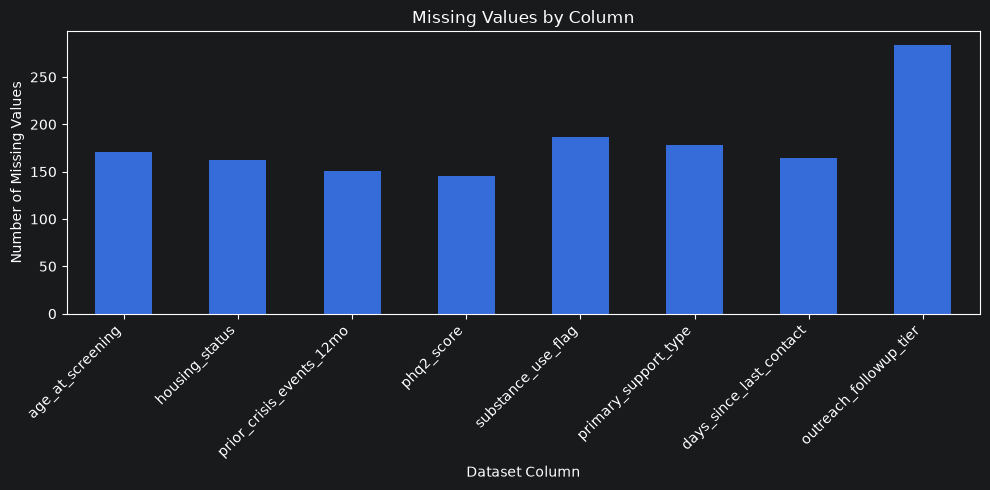

In [13]:
#Count Missing Values in Each Column
missing_counts = df.isnull().sum()

#Keep Columns that have Missing Values
missing_counts = missing_counts[missing_counts > 0]

#Create a Bar Chart
missing_counts.plot(kind="bar", figsize=(10, 5))

#Add Title and Labels
plt.title("Missing Values by Column")
plt.xlabel("Dataset Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")

#Adjust Spacing and Display the Chart
plt.tight_layout()
plt.show()

Figure 1: Missing Values by Columns:
The bar chart above shows the amount of missing values in each column in the dataset. Like mention previously the outreach_followup_tier column has the most missing values, while phq2_score has the lowest missing value.

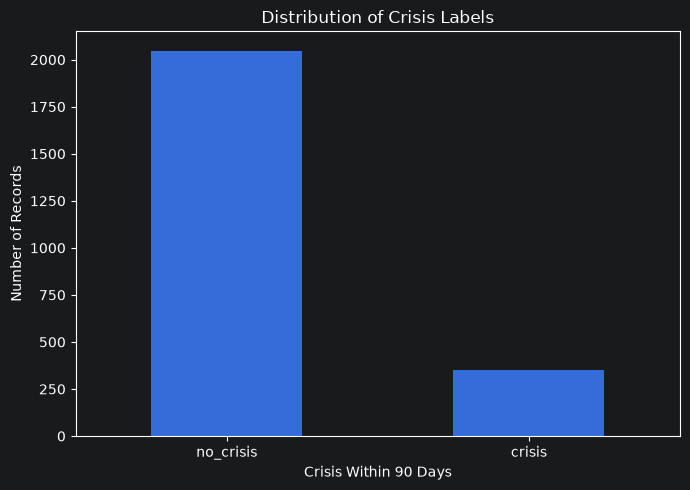

Target Class Counts:
crisis_within_90_days
no_crisis    2048
crisis        352


In [8]:
#Count each Target Label
target_counts = df["crisis_within_90_days"].value_counts()

#Create a Bar Chart
target_counts.plot(kind="bar", figsize=(7, 5))

#Add Chart Title and Labels
plt.title("Distribution of Crisis Labels")
plt.xlabel("Crisis Within 90 Days")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

#Display the Chart and Counts
plt.tight_layout()
plt.show()
print("Target Class Counts:")
print(target_counts.to_string())

Figure 2: Crisis Labels Distribution:
The bar graph above shows the distribution of the target variable, crisis_within_90_days. Out of the 2,400 records, there are 2,048 are labeled no_crisis and 352 are labeled crisis. This means there is approximately 85.3% of the records is under no_crisis and 14.7% is under the crisis. This shows that there is an imbalance because the no_crisis is much more common. Bringing into account that this imbalance should be considered when evaluating the model.

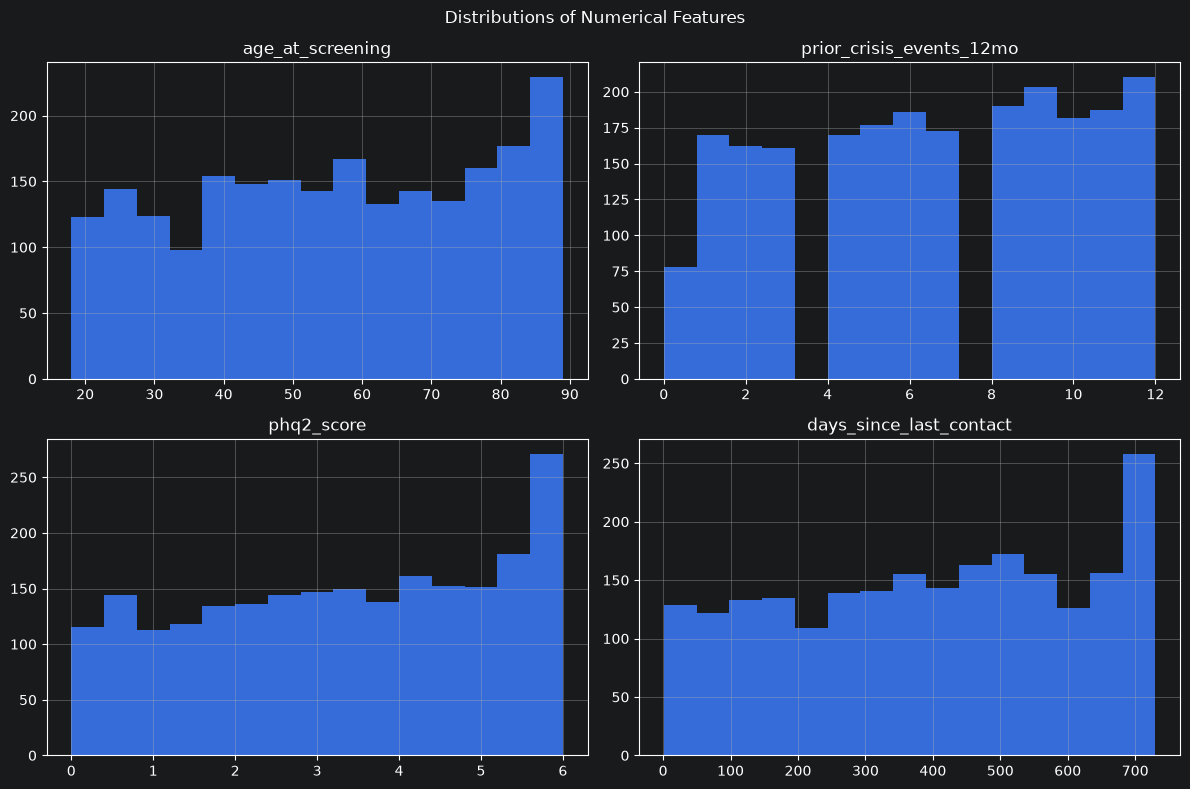

In [9]:
#Select Numerical Columns we Want to Examine
numerical_columns = [
    "age_at_screening",
    "prior_crisis_events_12mo",
    "phq2_score",
    "days_since_last_contact"
]

#Create a Histogram for Each Numerical Column
df[numerical_columns].hist(figsize=(12, 8), bins=15)

#Add a Title and Layout
plt.suptitle("Distributions of Numerical Features")
plt.tight_layout()
plt.show()

Figure 3: Numerical Features Distributions:
The histograms above shows the distributions of 4 of the numerical features:age_at_screening,prior_crisis_events_12mo, phq2_score, and days_since_last_contact. The histograms help visualize and identify the common value ranges, patterns, and potentially unusual values. These features will be examined further to determine whether data-quality issues need to be addressed before model training.

In [6]:
#Check Minimum and Maximum Values for Each Numerical Feature

for column in numerical_columns:
    print(f"\n{column}")
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())


age_at_screening
Minimum: 18.0
Maximum: 89.0

prior_crisis_events_12mo
Minimum: 0.0
Maximum: 12.0

phq2_score
Minimum: 0.0
Maximum: 6.0

days_since_last_contact
Minimum: 1.0
Maximum: 730.0


Numerical Feature Range Checks:
The minimum and maximum checks did not reveal any obvious range problems within the 4 numerical features. The age range is from 18 to 89, the prior_crisis_events_12mo range from 0 to 12, the phq_2 scores range from 0 to 6, and the days_since_last_contact range from 1 to 730 days. These results suggest that the observed ranges are plausible, however further checks may be needed to confirm the data quality.

In [7]:
categorical_columns = [
    "region",
    "housing_status",
    "substance_use_flag",
    "primary_support_type"
]

#Print Number of Records in Each Category
for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False).to_string())


--- region ---
region
Gulf Coast       799
Metro North      738
Inland Valley    730
Delta Basin      133

--- housing_status ---
housing_status
stable_housed           1584
doubled_up               236
transitional             221
unstable_or_unhoused     197
NaN                      162

--- substance_use_flag ---
substance_use_flag
False    1131
True     1082
NaN       187

--- primary_support_type ---
primary_support_type
case_manager       1578
none_reported       180
NaN                 178
peer_support        161
family_only         152
faith_community     151


Categorical Feature Summary:
The categorical feature counts shows the differences in how the records are distributed across categories and regions. Gulf Coast has the most records, while Delta Basin has the fewest. The most common housing is the stable_house. For the substance_use_flag there are 1,131 reported they don't use substance while 1,082 reported they do. The most common primary support type is case_manager. While missing values are also present in the housing status and primary support type. It is important to take into account the missing values and difference during the data preparation.

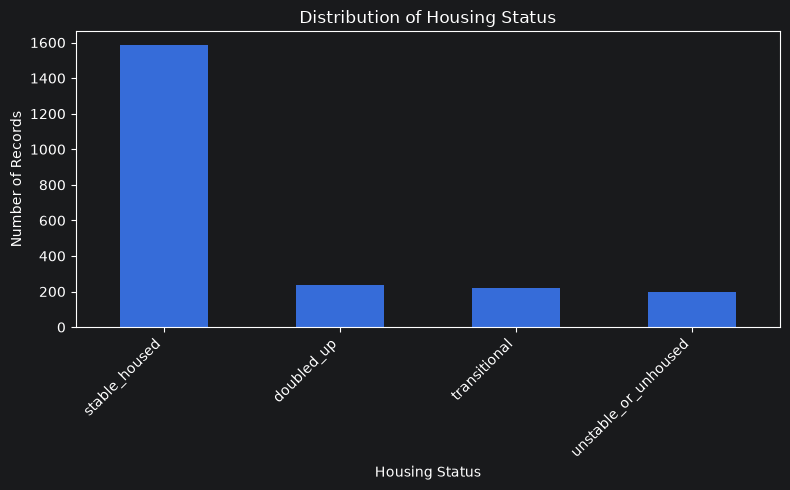

In [10]:
#Count Records in Each Housing Category and Create a Bar Chart
df["housing_status"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

#Add the Chart Title and Axis Labels
plt.title("Distribution of Housing Status")
plt.xlabel("Housing Status")
plt.ylabel("Number of Records")

#Rotate Category Labels
plt.xticks(rotation=45, ha="right")

#Adjust the Layout and Display the Chart
plt.tight_layout()
plt.show()

Figure 4: Housing Status Distribution:
The bar chart above shows the distribution of the housing status. As we can see the most common category is the stable_housed and the least common one is unstable_or_unhoused. There are also 162 missing values, which are not being displayed. The housing status may provide useful information to predict the crisis risk, but this possibility must be evaluated during model development rather than assumed.

In [2]:
#Count Each Follow Up tier (Including Missing Values)
print("Outreach Follow-Up Tier Counts:")
print(df["outreach_followup_tier"].value_counts(dropna=False).to_string())

Outreach Follow-Up Tier Counts:
outreach_followup_tier
no_crisis    1800
crisis        316
NaN           284


Potential Data Leakage in outreach_followup_tier:
The outreach_followup_tier column contains 1,800 records labeled no_crisis, 316 labeled crisis, and 284 missing values. These category labels closely match the target variable, crisis_within_90_days. This raises a concern about there being a potential data leakage.The timing and process used to assign this field must be confirmed. For the initial model, this feature should be excluded until its availability and relationship to the target are clarified.

In [4]:
#Keep Rows Where Both Columns Have Values
comparison_df = df[
    df["outreach_followup_tier"].notna()
    & df["crisis_within_90_days"].notna()
]

#Count Matching and Non-matching Labels
matching_labels = (
    comparison_df["outreach_followup_tier"]
    == comparison_df["crisis_within_90_days"]
)

print("Records with Both Values:", len(comparison_df))
print("Matching Labels:", matching_labels.sum())
print("Non-matching Labels:", (~matching_labels).sum())
print("Percentage Matching:", round(matching_labels.mean() * 100, 2), "%")

Records with Both Values: 2116
Matching Labels: 1979
Non-matching Labels: 137
Percentage Matching: 93.53 %


Follow Up Tier and Target Comparison:
A comparison of outreach_followup_tier and crisis_within_90_days found out that 1,979 out of 2,116 records with both values had matching labels, coming to a 93.53% agreement. Leaving the remaining 137 records having different labels. Having this high level of agreement raises a signigicant concern that the outreach_followup_tier may contain information that is closely related to the target variable. However, the comparison alone does not establish whether data leakage has happened.

Initial Hypotheses:
1. Class imbalance: Since there is only a 14.7% records that are labeled crisis, having a model evaluation should consider with how effectively the model identifies crisis cases.
2. Missing data: Missing values may reflect the differences in intake practices, coordinator workflows, or regional procedures rather than occurring randomly.
3. Prior Crisis Events: Clients with more crisis events in the previous 12 months may be more likely to experience another crisis within 90 days.
4. PHQ-2 Score: Higher PHQ-2 scores may be associated with a greater likelihood of a crisis within 90 days.
5. Housing Status: Having housing instability may be associated with crisis risk.
6. Regional Representation: Delta Basin has substantially fewer records than the other regions, which may limit how reliably model performance can be assessed for that region.
7. Potential Data Leakage: The outreach_followup_tier feature matches the target label in 93.53% of records where both are present. Its assignment process and timing need to be confirmed, and it will be excluded from the initial model until then.

These hypotheses will be investigated during later analysis and model development. The model's predictions should help prioritize outreach efforts while allowing professionals to make the final decisions.